# 05 · A fill model that sees the book

Notebook 04 ended with two facts. The constant fill probability is wrong in a predictable way (assumed 0.61; obtained
0.64 after a fill, 0.46 after two misses). And with a constant probability, MPC makes exactly the decisions of a
two-threshold rule: the optimisation adds nothing.

This notebook gives the QP a fill probability that depends on the book, and asks whether the optimisation then earns
its keep. Five questions:
1. what the model is, and what its coefficients say;
2. whether it is calibrated on a simulation it has never seen;
3. what the QP does differently when it is given this model;
4. whether that lowers the cost of execution, or improves how the schedule is followed;
5. whether, at equal deviation from the schedule, the informed QP trades at a lower cost.

In [1]:
%reload_ext autoreload
%autoreload 2
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mpc_execution.book import Side
from mpc_execution.simulator import SimParams
from mpc_execution.schedule import twap
from mpc_execution.fills import collect_fill_samples, ConstantFill, LogisticFill, design_matrix, sigmoid
from mpc_execution.calibration import brier, log_loss, reliability_table
from mpc_execution.mpc import MPC, MPCParams
from mpc_execution.experiment import run_many
from mpc_execution.metrics import summarize, deviation, fwap, swap

FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
Q, N, DT, N_ORDERS = 500, 20, 5.0, 200
N_LEVELS, QTY = 5, 25
params, schedule, k = SimParams(), twap(Q, N), np.arange(N + 1)

### 1. Data and models

The training sample is the one of notebooks 03 and 04: 2,000 trials, five price levels, 25 shares, one step of
`dt` = 5 (seed 0). Each row is one limit order: what the book looked like when it was posted, and the fraction of
it that was executed. Two models are fitted on it:

- **constant**: the average executed fraction per level, whatever the book (the paper's model, used in notebook 04);
- **logistic**: a formula of the queue ahead, the level and the spread (D25).

A second sample, from a different seed, is never used for fitting. It is there to judge the models (D26).

In [2]:
%%time
train = collect_fill_samples(params, N_LEVELS, QTY, DT, 2000, seed=0)
test = collect_fill_samples(params, N_LEVELS, QTY, DT, 2000, seed=1)
constant = ConstantFill.from_samples(train)
logistic = LogisticFill.from_samples(train)
print(len(train), "training rows,", len(test), "test rows")
print("constant pi by level:", constant.pi.round(3))

10000 training rows, 10000 test rows
constant pi by level: [0.606 0.115 0.037 0.018 0.008]
CPU times: user 17.9 s, sys: 340 ms, total: 18.2 s
Wall time: 18 s


### 2. The model

For an order posted at level $j$ (0 is our touch):

$$\pi_j = \sigma\big(\beta_0 + \beta_1 \log(1 + \text{shares ahead}_j) + \beta_2\, j + \beta_3\,[\text{spread} > 1]\big),
\qquad \sigma(z) = \frac{1}{1 + e^{-z}} .$$

"Shares ahead" is everything on our side of the book with price or time priority over the order. The coefficients are
found by Newton's method on the cross-entropy, with the executed fraction as outcome, so partial fills are used as they
are. A coefficient acts on the *odds* $\pi / (1 - \pi)$: adding $\beta$ to the argument multiplies the odds by $e^{\beta}$.

**Expectation.** Notebook 03 measured a fill probability at the touch going from 0.88 with a short queue to 0.21 with
a long one, and 0.47 against 0.61 when the spread is two ticks. So $\beta_1$ should be clearly negative, and $\beta_2$,
$\beta_3$ negative as well.

In [3]:
b = logistic.beta
pd.DataFrame({"beta": b,
              "odds multiplied by": [np.nan, 2 ** b[1], np.exp(b[2]), np.exp(b[3])],
              "when": ["", "the queue ahead doubles", "the order is one level further back", "the spread is wider than one tick"]},
             index=["intercept", "log(1 + shares ahead)", "level", "spread > 1"]).round(3)

,beta,odds multiplied by,when
intercept,7.108,NaN,
log(1 + shares ahead),-1.249,0.421,the queue ahead doubles
level,-1.367,0.255,the order is one level further back
spread > 1,-1.110,0.330,the spread is wider than one tick


In [4]:
queues = np.array([0, 30, 100, 250, 500, 850])
at_touch = lambda spread: sigmoid(design_matrix(queues, np.zeros(len(queues)), np.full(len(queues), spread)) @ b)
pd.DataFrame({"shares ahead": queues, "pi at the touch, spread 1": at_touch(1), "pi at the touch, spread 2": at_touch(2)}).round(3)

,shares ahead,"pi at the touch, spread 1","pi at the touch, spread 2"
0,0,0.999,0.998
1,30,0.944,0.847
2,100,0.793,0.558
3,250,0.551,0.288
4,500,0.341,0.146
5,850,0.211,0.081


**Result.** The three effects have the expected sign, and they are large.
- Doubling the queue ahead multiplies the odds of a fill by 0.42. At the touch, with a one-tick spread, the model gives
  0.94 with 30 shares ahead, 0.55 with 250 and 0.21 with 850; notebook 03 measured 0.88 and 0.21 at the two ends.
- One level further back multiplies the odds by 0.26, over and above the longer queue.
- A spread wider than one tick multiplies them by 0.33: with 250 shares ahead the probability falls from 0.55 to 0.29.
  With a two-tick spread new limit orders arrive inside the spread, in front of ours (notebook 03).
- The constant model's 0.61 is what this model says for a queue of about 200 shares. Around it, the probability moves
  between 0.2 and 0.95.

### 3. Is it calibrated on fresh data?

A probability model is judged on two things. *Calibration*: among the orders it gives 70%, do 70% fill? *Sharpness*:
does it tell apart orders that fill from orders that do not? Two scores measure both at once, lower is better:

- **Brier score**: the mean squared difference between prediction and outcome. A model that always says the average
  gets the variance of the outcome;
- **log-loss**: the cross-entropy, which punishes confident mistakes much harder.

"Brier skill" is the share of the constant model's Brier score that the logistic removes.

**Expectation.** At the touch, a skill close to 19%: that is the share of the outcome variance that ten groups of
queue length explained in notebook 03. The rest is the order flow during the step, which nothing in the book predicts.

In [5]:
def predict(model, d):
    # Predicted executed fraction for every row of a sample table.
    if isinstance(model, ConstantFill):
        return model.pi[d.level.to_numpy()]
    return sigmoid(design_matrix(d.shares_ahead, d.level, d.spread) @ model.beta)

rows = []
for label, d in [("all levels", test), ("touch only", test[test.level == 0])]:
    y = d.filled_frac.to_numpy()
    for name, model in [("constant", constant), ("logistic", logistic)]:
        p = predict(model, d)
        rows.append({"rows": label, "model": name, "brier": brier(y, p), "log_loss": log_loss(y, p)})
scores = pd.DataFrame(rows).set_index(["rows", "model"])
scores["brier skill"] = 1 - scores.brier / scores.brier.groupby(level="rows").transform("first")
scores.round(4)

brier  log_loss  brier skill
rows       model                                  
all levels constant  0.0724    0.2457       0.0000
           logistic  0.0627    0.2179       0.1337
touch only constant  0.2283    0.6710       0.0000
           logistic  0.1870    0.5802       0.1809

The reliability diagram shows calibration directly. The touch orders of the test sample are sorted by predicted
probability and cut into ten groups of equal size; each point is one group, with the average prediction on the
horizontal axis and the executed fraction actually observed on the vertical one. A calibrated model lies on the diagonal.
The constant model is a single point: it makes one prediction for every order.

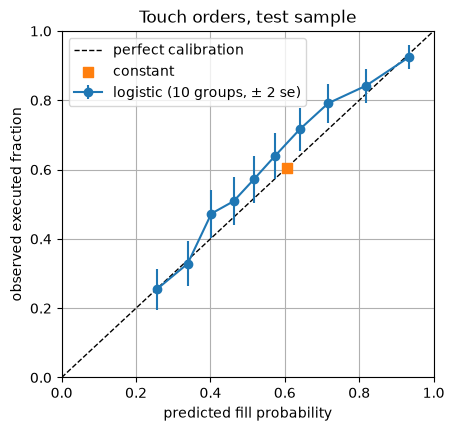

,predicted,observed,sem,count
0,0.255,0.254,0.030,200
1,0.339,0.328,0.033,200
2,0.403,0.473,0.035,200
3,0.462,0.509,0.035,200
4,0.517,0.572,0.034,200
5,0.573,0.639,0.033,200
6,0.640,0.716,0.031,200
7,0.717,0.792,0.028,200
8,0.819,0.842,0.025,200
9,0.934,0.925,0.018,200


In [6]:
d0 = test[test.level == 0]
rel = reliability_table(d0.filled_frac.to_numpy(), predict(logistic, d0), n_bins=10)
fig, ax = plt.subplots(figsize=(4.8, 4.5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.errorbar(rel.predicted, rel.observed, yerr=2 * rel["sem"], marker="o", label="logistic (10 groups, ± 2 se)")
ax.scatter([constant.pi[0]], [d0.filled_frac.mean()], marker="s", s=60, color="C1", zorder=3, label="constant")
ax.set(xlabel="predicted fill probability", ylabel="observed executed fraction",
       title="Touch orders, test sample", xlim=(0, 1), ylim=(0, 1))
ax.grid()
ax.legend()
fig.savefig(FIG / "05_reliability.png", dpi=150, bbox_inches="tight")
plt.show()
rel.round(3)

**Result.**
- At the touch the logistic model removes 18% of the constant model's Brier score (0.228 → 0.187), against the 19%
  expected; over the five levels together, 13% (0.072 → 0.063). The log-loss improves in the same proportion
  (0.67 → 0.58 at the touch).
- Calibration is good at the two ends and slightly off in the middle: for predictions between 0.40 and 0.72 the observed
  fraction is 0.05–0.08 higher than predicted, about two standard errors in each of six consecutive groups. On average
  the model is 0.04 too low at the touch (0.57 predicted, 0.61 observed).
- The cause is the shape imposed on the queue effect, a single logarithmic slope shared by all levels; the next figure
  shows where it bends away from the data. The error is small next to the constant model's, which is off by up to 0.35
  in either direction, but it is systematic: a second version of the model should remove it.

The curve of notebook 03 again, on the test sample, with the model drawn over the data: executed fraction at the touch
against the shares ahead. The dashed line is what the constant model says for every order.

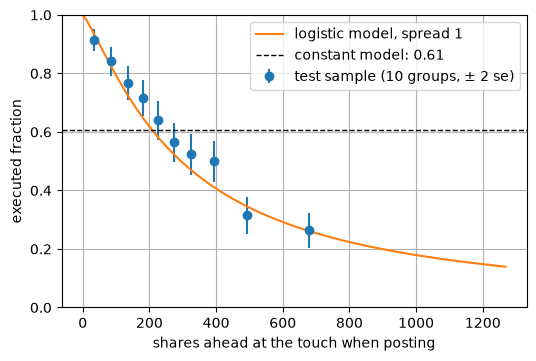

In [7]:
d0 = d0.assign(group=pd.qcut(d0.shares_ahead, 10, duplicates="drop"))
curve = d0.groupby("group", observed=True).agg(ahead=("shares_ahead", "mean"), observed=("filled_frac", "mean"),
                                               sem=("filled_frac", "sem"))
grid = np.linspace(0, d0.shares_ahead.max(), 200)
model_curve = sigmoid(design_matrix(grid, np.zeros(len(grid)), np.ones(len(grid))) @ logistic.beta)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.errorbar(curve.ahead, curve.observed, yerr=2 * curve["sem"], fmt="o", label="test sample (10 groups, ± 2 se)")
ax.plot(grid, model_curve, label="logistic model, spread 1")
ax.axhline(constant.pi[0], ls="--", color="k", lw=1, label=f"constant model: {constant.pi[0]:.2f}")
ax.set(xlabel="shares ahead at the touch when posting", ylabel="executed fraction", ylim=(0, 1))
ax.grid()
ax.legend()
fig.savefig(FIG / "05_fill_vs_queue.png", dpi=150, bbox_inches="tight")
plt.show()

**Result.** The model follows the data at short queues (0.91 with ≈35 shares ahead) and at long ones (0.26 with ≈680),
and runs below them in between: with ≈400 shares ahead it says 0.41 where the data say 0.50. The logarithm is too
curved: up to ≈500 shares the data fall almost in a straight line. The constant model is right only near 250 shares.

### 4. Inside the controller

The same 200 orders as notebooks 02 and 04 (same seeds), executed twice by MPC: once with the constant model, once
with the logistic one. Everything else is identical, so any difference comes from what the QP is told about fills.
Two settings of the penalty:

- `gamma` = 0.02, the default. Here MPC with the constant model *is* the threshold rule (notebook 04), and its row must
  reproduce notebook 04: shortfall −0.19 bp, passive share 0.87;
- `gamma` = 0.1, where the penalty is strong enough to change the orders even with the constant model: it moves part
  of the quantity behind the touch (see below).

Two small wrappers record what is needed to understand the result. `RecordingFill` keeps the probabilities the QP was
given at every step. `Shadow` asks, at every step of the logistic run, what MPC with the constant model would have sent
*in the same state*; the two runs themselves cannot be compared step by step, because their books diverge after the
first different decision.

**Expectation**, from solving the QP by hand. At `gamma` = 0.02 a high probability changes nothing: the upper tube
already binds. A low one does: when $\pi_0 < 0.29$ with a gap of 25, or $\pi_0 < 0.42$ with a gap of 50, the QP sends
part of the gap to market at once instead of posting an order that will probably miss. About a quarter of the decisions
should differ. Whether this lowers the cost is not obvious: a market order sent early pays the spread now, to avoid
falling behind and paying it later at a worse price. At `gamma` = 0.1 the passive quantity itself depends on the
probability, so more decisions should differ.

In [8]:
class Factory:
    # Builds a fresh policy per order and keeps them, to read their records afterwards.
    def __init__(self, make):
        self.make, self.made = make, []

    def __call__(self):
        self.made.append(self.make())
        return self.made[-1]

class RecordingFill:
    # Wraps a fill model and keeps every probability vector it returns.
    def __init__(self, model):
        self.model, self.seen = model, []

    def probs(self, state, side, qty):
        pi = np.asarray(self.model.probs(state, side, qty), dtype=float)
        self.seen.append(pi.copy())
        return pi

class Shadow:
    # Runs `policy` and records its orders at every step; with `other`, also what `other` would have sent in the same state.
    def __init__(self, policy, other=None):
        self.policy, self.other, self.steps = policy, other, []

    def decide(self, state, side, q, target, remaining):
        mine = self.policy.decide(state, side, q, target, remaining)
        theirs = None if self.other is None else self.other.decide(state, side, q, target, remaining)
        touch = state.best_bid if side == Side.BUY else state.best_ask
        self.steps.append({"gap": target - q, "touch": touch, "mine": mine, "theirs": theirs})
        return mine

RHO_LOW = MPCParams().rho_low

def decompose(r):
    x, ds, m = np.diff(r.filled_path), np.diff(r.schedule), r.mids[:-1]
    timing = r.side.value * np.sum((x - ds) * m) / r.Q            # executing at other times than scheduled
    total = r.side.value * (fwap(r) - swap(r))
    return {"spread_capture_bps": 1e4 * (total - timing) / swap(r), "timing_bps": 1e4 * timing / swap(r)}

def run(policy_factory, n_orders=N_ORDERS):
    res = run_many(params, policy_factory, dt=DT, schedule=schedule, n_orders=n_orders, seed0=0)
    df = pd.DataFrame(map(summarize, res))
    dev = np.array([deviation(r) for r in res])[:, 1:-1]
    df["passive_share"] = [sum(e.qty for e in r.executions if e.passive) / r.filled for r in res]
    df["mean_deviation"] = dev.mean(1)
    df["rms_deviation"] = np.sqrt((dev ** 2).mean(1))
    df["steps_at_lower_edge"] = (dev <= -RHO_LOW + 1).mean(1)
    return res, df.join(pd.DataFrame(map(decompose, res)))

COLS = ["schedule_shortfall_bps", "spread_capture_bps", "timing_bps", "arrival_slippage_bps",
        "passive_share", "mean_deviation", "rms_deviation", "steps_at_lower_edge", "completion"]
mean_se = lambda d: pd.DataFrame({"mean": d.mean(), "se": d.sem()})

def compare(df_a, df_b, a="constant pi", b="logistic pi"):
    # Means with standard errors, and the difference paired by order (same seed and side).
    return pd.concat({a: mean_se(df_a[COLS]), b: mean_se(df_b[COLS]),
                      f"{b} − {a}": mean_se(df_b[COLS] - df_a[COLS])}, axis=1).round(3)

In [9]:
%%time
runs = {}
for gamma in (0.02, 0.1):                 # four runs of 200 orders: a few minutes
    p = MPCParams(gamma=gamma)
    f_const = Factory(lambda p=p: Shadow(MPC(constant, p)))            # here Shadow only records the orders sent
    f_logit = Factory(lambda p=p: Shadow(MPC(RecordingFill(logistic), p), MPC(constant, p)))
    res_c, df_c = run(f_const)
    res_l, df_l = run(f_logit)
    runs[gamma] = {"p": p, "res_c": res_c, "df_c": df_c, "res_l": res_l, "df_l": df_l,
                   "shadows": f_logit.made, "shadows_c": f_const.made}
    print(f"gamma = {gamma}: solver fallbacks, constant {sum(s.policy.n_fallbacks for s in f_const.made)},",
          f"logistic {sum(s.policy.n_fallbacks for s in f_logit.made)}")

gamma = 0.02: solver fallbacks, constant 0, logistic 0
gamma = 0.1: solver fallbacks, constant 0, logistic 0
CPU times: user 2min 44s, sys: 674 ms, total: 2min 45s
Wall time: 2min 45s


In [10]:
for gamma, r_ in runs.items():
    print(f"gamma = {gamma}")
    display(compare(r_["df_c"], r_["df_l"]))

gamma = 0.02


constant pi        logistic pi         \
                              mean     se        mean     se   
schedule_shortfall_bps      -0.185  0.020      -0.179  0.018   
spread_capture_bps          -0.382  0.009      -0.392  0.011   
timing_bps                   0.196  0.016       0.213  0.016   
arrival_slippage_bps         0.449  0.195       0.477  0.212   
passive_share                0.868  0.008       0.824  0.008   
mean_deviation               5.416  0.665       4.488  0.496   
rms_deviation               25.547  0.282      22.957  0.195   
steps_at_lower_edge          0.088  0.007       0.029  0.003   
completion                   1.000  0.000       1.000  0.000   

                       logistic pi − constant pi         
                                            mean     se  
schedule_shortfall_bps                     0.007  0.022  
spread_capture_bps                        -0.010  0.010  
timing_bps                                 0.017  0.019  
arrival_slippage_bps                       0.028  0.147  
passive_share                             -0.044  0.009  
mean_deviation                            -0.928  0.591  
rms_deviation                             -2.590  0.278  
steps_at_lower_edge                       -0.060  0.007  
completion                                 0.000  0.000

gamma = 0.1


constant pi        logistic pi         \
                              mean     se        mean     se   
schedule_shortfall_bps      -0.139  0.021      -0.101  0.021   
spread_capture_bps          -0.394  0.011      -0.333  0.013   
timing_bps                   0.256  0.018       0.232  0.019   
arrival_slippage_bps         0.577  0.218       0.890  0.261   
passive_share                0.831  0.008       0.733  0.009   
mean_deviation              -1.191  0.575       1.199  0.364   
rms_deviation               24.226  0.349      18.849  0.165   
steps_at_lower_edge          0.091  0.007       0.009  0.002   
completion                   1.000  0.000       1.000  0.000   

                       logistic pi − constant pi         
                                            mean     se  
schedule_shortfall_bps                     0.038  0.024  
spread_capture_bps                         0.062  0.014  
timing_bps                                -0.024  0.022  
arrival_slippage_bps                       0.313  0.232  
passive_share                             -0.098  0.010  
mean_deviation                             2.390  0.561  
rms_deviation                             -5.377  0.372  
steps_at_lower_edge                       -0.083  0.008  
completion                                 0.000  0.000

**Result.**
- Check: with the constant model and `gamma` = 0.02 the run reproduces notebook 04 (shortfall −0.19 bp, passive share
  0.87). No solver fallback in any of the four runs.
- **Cost does not improve.** Schedule shortfall with the logistic model minus the constant one, paired by order:
  +0.007 ± 0.022 bp at `gamma` = 0.02 and +0.038 ± 0.024 at `gamma` = 0.1. No measurable change in arrival slippage
  either (+0.03 ± 0.15 and +0.31 ± 0.23).
- **The schedule is followed more closely.** RMS deviation falls by 2.6 ± 0.3 shares (−10%) and by 5.4 ± 0.4 (−22%).
  The share of decision times at the lower edge of the tube, where market orders are forced, falls from 8.8% to 2.9%
  and from 9.1% to 0.9%.
- How: the QP relies less on passive orders (passive share −4.4 and −9.8 points) and sends market orders earlier. At
  `gamma` = 0.02 this costs nothing in spread capture (−0.010 ± 0.010); at 0.1 it costs 0.062 ± 0.014.
- The timing cost, which a better fill model was expected to reduce, does not move (+0.017 ± 0.019 and −0.024 ± 0.022).

Knowing that an order is unlikely to fill does not make it cheaper to fill. The alternative is a market order, which
pays half a spread now instead of later. The information is used to avoid falling behind, not to trade at a better price.

**The price of `gamma` = 0.1, measured on 200 orders.** Notebook 04 compared the two settings of the penalty on 100
orders and found no measurable difference in cost. The four runs above allow the same comparison on 200 orders, paired
by order, for each fill model.

In [11]:
pd.concat({name: mean_se(runs[0.1][key][COLS] - runs[0.02][key][COLS])
           for name, key in [("constant pi", "df_c"), ("logistic pi", "df_l")]}, axis=1).round(3)

constant pi        logistic pi       
                              mean     se        mean     se
schedule_shortfall_bps       0.047  0.023       0.078  0.023
spread_capture_bps          -0.012  0.010       0.059  0.015
timing_bps                   0.059  0.019       0.019  0.021
arrival_slippage_bps         0.128  0.177       0.413  0.206
passive_share               -0.037  0.008      -0.091  0.010
mean_deviation              -6.606  0.552      -3.289  0.518
rms_deviation               -1.320  0.298      -4.108  0.247
steps_at_lower_edge          0.003  0.006      -0.020  0.003
completion                   0.000  0.000       0.000  0.000

**Result.** `gamma` = 0.1 is not free.
- With the constant model it raises the shortfall by 0.047 ± 0.023 bp, entirely through the timing cost
  (+0.059 ± 0.019). In exchange the order is centred on its schedule (mean deviation −6.6 shares, from 5.4 ahead to 1.2
  behind) and the RMS deviation falls by 1.3 shares.
- With the logistic model it costs 0.078 ± 0.023 bp, this time through spread capture (+0.059 ± 0.015), and the RMS
  deviation falls by 4.1 shares.

Notebook 04 found no measurable cost on 100 orders (−0.18 against −0.17, standard error 0.03 each). With twice the
orders and the difference paired by order, it is visible at two standard errors. The sentence in notebook 04 that
called the centring "free" has been corrected.

**What the QP does differently.** One row per decision of the logistic runs: what MPC sent, what it would have sent
with the constant model in the same state, and the touch probability it was given. The table splits the decisions in
two: those where the two models lead to the same orders, and those where they do not.

In [12]:
def qty(orders, kind):
    return sum(o.qty for o in orders if o.kind == kind)

def decisions(r_):
    # One row per decision of the logistic run. Steps after the order is complete carry no probabilities and are dropped.
    rows = []
    for i, (s, r) in enumerate(zip(r_["shadows"], r_["res_l"])):
        filled = np.diff(r.filled_path)
        for step, (d, pi) in enumerate(zip(s.steps, s.policy.fill_model.seen)):
            limits = [(abs(o.price - d["touch"]), o.qty) for o in d["mine"] if o.kind == "limit"]   # (level, shares)
            market = qty(d["mine"], "market")
            rows.append({"order": i, "step": step, "gap": d["gap"], "pi_touch": pi[0],
                         "market": market, "limit": qty(d["mine"], "limit"),
                         "market_const": qty(d["theirs"], "market"), "limit_const": qty(d["theirs"], "limit"),
                         "differs": d["mine"] != d["theirs"],
                         "deepest_level": max((lvl for lvl, _ in limits), default=0),
                         "expected_passive": sum(pi[lvl] * n for lvl, n in limits),
                         "passive_filled": filled[step] - market})
    return pd.DataFrame(rows)

for gamma, r_ in runs.items():
    d = r_["decisions"] = decisions(r_)
    print(f"gamma = {gamma}: {d.differs.mean():.1%} of {len(d)} decisions differ from MPC with the constant model;",
          f"deepest level used: {d.deepest_level.max()}")
    display(d.groupby("differs")[["pi_touch", "gap", "market", "market_const", "limit", "limit_const"]].mean().round(2))

gamma = 0.02: 35.9% of 3932 decisions differ from MPC with the constant model; deepest level used: 2


,pi_touch,gap,market,market_const,limit,limit_const
differs,,,,,,
False,0.52,21.05,3.09,3.09,41.65,41.65
True,0.63,21.18,6.95,1.77,39.23,44.41


gamma = 0.1: 87.9% of 3954 decisions differ from MPC with the constant model; deepest level used: 2


,pi_touch,gap,market,market_const,limit,limit_const
differs,,,,,,
False,0.58,32.89,11.25,11.25,38.58,38.58
True,0.56,22.94,6.12,0.62,41.81,47.32


At the default `gamma` = 0.02, MPC with the constant model never posts behind the touch (notebook 04). Where the
passive shares are posted, by level, for both models and both settings of the penalty:

In [13]:
def level_shares(shadows):
    total = np.zeros(3)
    for s in shadows:
        for d in s.steps:
            for o in d["mine"]:
                if o.kind == "limit":
                    total[abs(o.price - d["touch"])] += o.qty
    return total / total.sum()

pd.DataFrame({(f"gamma = {gamma}", name): level_shares(r_[key]) for gamma, r_ in runs.items()
              for name, key in [("constant pi", "shadows_c"), ("logistic pi", "shadows")]},
             index=["at the touch", "one tick behind", "two ticks behind"]).round(3)

gamma = 0.02             gamma = 0.1            
                  constant pi logistic pi constant pi logistic pi
at the touch              1.0       0.904       0.812       0.729
one tick behind           0.0       0.095       0.188       0.259
two ticks behind          0.0       0.001       0.000       0.012

**Result.**
- 36% of the decisions differ at `gamma` = 0.02, where a quarter was expected, and 88% at `gamma` = 0.1.
- The expectation was only half right about the reason. The decisions that differ do not have a lower touch probability
  (0.63 on average, against 0.52 for those that agree): the QP changes its orders both when the queue is long and when
  the book is thin.
- When it differs, it sends more to market (7.0 shares against 1.8 at `gamma` = 0.02; 6.1 against 0.6 at 0.1) and posts
  less (39 against 44; 42 against 47).
- At `gamma` = 0.02 it also posts behind the touch, which the constant model never does: 10% of the passive shares are
  one tick behind. A fill one tick behind is worth twice as much to the QP (it earns 1.5 spreads instead of 0.5), so
  with the tube binding the level is chosen whenever its fill probability exceeds half the touch's. With constant
  probabilities that never happens (0.12 against 0.61); with a model of the queue it does, when the book near the touch
  is thin.
- This is why spread capture holds at `gamma` = 0.02 despite the lower passive share: fewer passive fills, each worth more.
- At `gamma` = 0.1 posting behind the touch is not specific to the model: the constant model does it too (19% of its
  passive shares, against 26%). The reason is different. The QP still posts everything the tube allows, because every
  limit candidate has a negative cost; to lower the quantity it *expects* to execute, as the penalty asks when the order
  is ahead of schedule, it moves the order one tick back, where a fill is less likely. The split between the touch and
  the level behind then depends continuously on the probabilities, which is why almost every decision (88%) differs
  between the two models at this setting.

With this model MPC is no longer a rule of the gap alone.

**Is the model still calibrated on the states MPC visits?** A controller does not visit book states at random: in
notebook 04 the constant model assumed 0.61 and obtained 0.64, 0.54 or 0.46 depending on the order's recent history.
The same check for the logistic model: at every step with a limit order, the fraction the QP expected to fill
against the fraction that did.

gamma = 0.02: assumed 0.509, obtained 0.516, Brier inside the loop 0.184, steps 3800
gamma = 0.1: assumed 0.402, obtained 0.401, Brier inside the loop 0.159, steps 3800


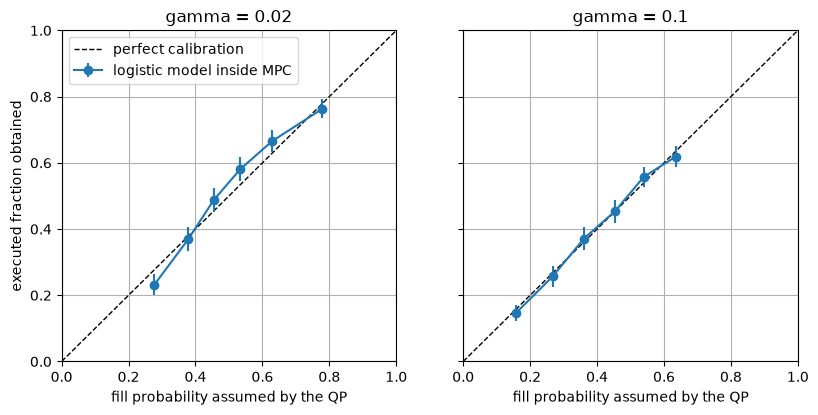

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.3), sharey=True)
for ax, (gamma, r_) in zip(axes, runs.items()):
    d = r_["decisions"]
    d = d[d.limit > 0]
    assumed, obtained = (d.expected_passive / d.limit).to_numpy(), (d.passive_filled / d.limit).to_numpy()
    rel = reliability_table(obtained, assumed, n_bins=6)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
    ax.errorbar(rel.predicted, rel.observed, yerr=2 * rel["sem"], marker="o", label="logistic model inside MPC")
    ax.set(title=f"gamma = {gamma}", xlabel="fill probability assumed by the QP", xlim=(0, 1), ylim=(0, 1))
    ax.grid()
    print(f"gamma = {gamma}: assumed {assumed.mean():.3f}, obtained {obtained.mean():.3f},",
          f"Brier inside the loop {brier(obtained, assumed):.3f}, steps {len(d)}")
axes[0].set_ylabel("executed fraction obtained")
axes[0].legend()
fig.savefig(FIG / "05_reliability_in_loop.png", dpi=150, bbox_inches="tight")
plt.show()

**Result.** Inside the loop the model is calibrated. The QP expected 0.509 of its passive shares to fill and obtained
0.516 at `gamma` = 0.02; 0.402 and 0.401 at `gamma` = 0.1. The points lie on the diagonal over the whole range, from
0.15 to 0.78; the slight under-prediction of section 3 is visible at `gamma` = 0.02 between 0.45 and 0.65.

With the constant model the QP assumed 0.61 at every step and obtained 0.64, 0.54 or 0.46 depending on the order's
recent history (notebook 04). That error is gone: the QP's expectations are now right on the states it visits. Together
with the previous result this separates two things that are easy to confuse: the model is better, and the cost is the same.

**Where the order sits around its schedule.** The share of decision times spent in each state, as in notebook 04:
one slice ahead, on schedule, one slice behind, two slices behind (the lower edge, where market orders are forced).

In [15]:
def states(res):
    dev = pd.Series(np.array([deviation(r) for r in res])[:, 1:-1].ravel())
    cut = pd.cut(dev, [-51, -37.5, -12.5, 12.5, 26], labels=["≈ −50", "≈ −25", "≈ 0", "≈ +25"])
    return cut.value_counts(normalize=True).sort_index(ascending=False)

pd.concat({(f"gamma = {gamma}", name): states(r_[key]) for gamma, r_ in runs.items()
           for name, key in [("constant pi", "res_c"), ("logistic pi", "res_l")]}, axis=1).round(3)

gamma = 0.02             gamma = 0.1            
       constant pi logistic pi constant pi logistic pi
≈ +25        0.553       0.497       0.378       0.320
≈ 0          0.217       0.257       0.334       0.418
≈ −25        0.128       0.185       0.157       0.235
≈ −50        0.103       0.061       0.131       0.027

**Result.** With the logistic model the order spends less time at both edges of the tube and more in the middle. At
`gamma` = 0.02: one slice ahead 55% → 50%, two slices behind 10% → 6%. At `gamma` = 0.1: 38% → 32% and 13% → 3%.
The lower edge is where market orders are forced; the model empties it by acting one or two steps earlier.

### 5. At equal deviation, is it cheaper?

Section 4 compares two points that differ in both cost and deviation, so it cannot say whether the model has any value
in terms of cost. The fair comparison is at equal deviation. Notebook 04 showed that the upper tube `rho_up` is the
lever that trades deviation for cost; here it is moved for both models (`gamma` = 0.02, `rho_low` = 50), which gives two
curves in the (deviation, cost) plane.

**Expectation.** If the model is worth something in cost, its curve lies below the constant model's at the same
deviation. From section 4 and the slope of the frontier in notebook 04 (about 0.02 bp per share of RMS deviation), the
gap should be of the order of 0.05 bp: close to what 200 orders can resolve.

In [16]:
%%time
rows = []
for rho_up in (0, 25, 50):                       # rho_up = 25 is the default, already run in section 4
    p = MPCParams(rho_up=rho_up)
    for name, model, key in [("constant pi", constant, "df_c"), ("logistic pi", logistic, "df_l")]:
        if rho_up == 25:
            d = runs[0.02][key]
        else:
            _, d = run(Factory(lambda p=p, model=model: MPC(model, p)))
        rows.append({"model": name, "rho_up": rho_up, "shortfall": d.schedule_shortfall_bps.mean(),
                     "se": d.schedule_shortfall_bps.sem(), "rms_dev": d.rms_deviation.mean(),
                     "lower_edge": d.steps_at_lower_edge.mean(), "passive": d.passive_share.mean()})
front = pd.DataFrame(rows).round(3)
front

CPU times: user 2min 23s, sys: 541 ms, total: 2min 24s
Wall time: 2min 24s


,model,rho_up,shortfall,se,rms_dev,lower_edge,passive
0,constant pi,0,-0.036,0.023,23.686,0.163,0.752
1,logistic pi,0,0.019,0.019,17.358,0.027,0.647
2,constant pi,25,-0.185,0.020,25.547,0.088,0.868
3,logistic pi,25,-0.179,0.018,22.957,0.029,0.824
4,constant pi,50,-0.244,0.024,32.866,0.066,0.894
5,logistic pi,50,-0.263,0.025,31.640,0.042,0.861


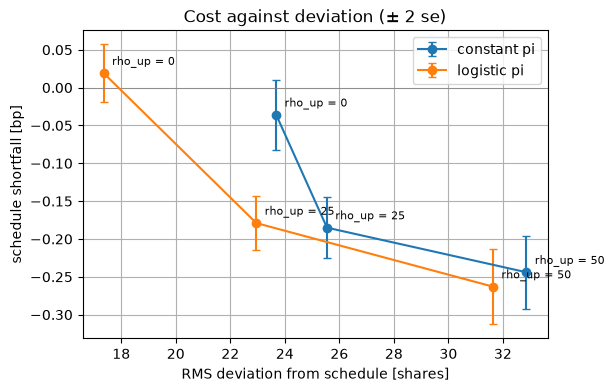

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, g in front.groupby("model"):
    ax.errorbar(g.rms_dev, g.shortfall, yerr=2 * g["se"], marker="o", capsize=3, label=name)
    for _, row in g.iterrows():
        ax.annotate(f"rho_up = {row['rho_up']:.0f}", (row["rms_dev"], row["shortfall"]),
                    textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.axhline(0, color="grey", lw=0.5)
ax.set(xlabel="RMS deviation from schedule [shares]", ylabel="schedule shortfall [bp]",
       title="Cost against deviation (± 2 se)")
ax.grid()
ax.legend()
fig.savefig(FIG / "05_frontier.png", dpi=150, bbox_inches="tight")
plt.show()

**Result.**
- At the same tubes the informed QP deviates less, at a cost that is equal within errors or slightly higher. RMS
  deviation and cost difference (logistic minus constant): 17.4 against 23.7 shares at `rho_up` = 0 (+0.055 ± 0.030 bp);
  23.0 against 25.5 at 25 (+0.007 ± 0.022); 31.6 against 32.9 at 50 (−0.019 ± 0.035). The tighter the upper tube, the
  larger the gain in deviation.
- Read at equal deviation, the two curves separate below ≈25 shares. The informed QP at its default setting
  (23.0 shares, −0.18 bp) has the deviation of the constant QP with `rho_up` = 0 (23.7 shares) and the cost of the
  constant QP with `rho_up` = 25 (−0.19 bp). Against the former it is 0.14 ± 0.03 bp cheaper.
- That figure holds the lower tube fixed. Notebook 04 shows that the constant model reaches a similar deviation more
  cheaply by tightening the lower tube instead (`rho_low` = 25, `rho_up` = 25: 21.7 shares at −0.10 bp, on 100 orders).
  Against that setting the gap is 0.05–0.08 bp.
- So at equal deviation the model is worth about 0.1 bp, in the low-deviation part of the frontier, and nothing above
  ≈30 shares. The expectation of 0.05 bp was of the right order.
- Time spent at the lower edge is where the model is unambiguous: 16% → 3%, 9% → 3% and 7% → 4% for the three tubes.

## Conclusions

1. **The model.** A fractional logit with four coefficients: the queue ahead, the level, the spread. Doubling the queue
   multiplies the odds of a fill by 0.42; at the touch the probability goes from 0.94 with 30 shares ahead to 0.21 with 850.
2. **It predicts better.** On a simulation it has never seen it removes 18% of the constant model's Brier score at the
   touch, close to the ceiling set by the queue itself (19%, notebook 03). It is 0.04 too low in the middle of the range:
   the logarithmic shape is too curved, and a second version should fix it.
3. **It stays calibrated inside the controller.** The QP assumed 0.51 and obtained 0.52, where with the constant model
   it assumed 0.61 and obtained between 0.46 and 0.64.
4. **It changes what the QP does**: 36% of the decisions at the default settings, 88% at `gamma` = 0.1. The QP sends
   market orders earlier when the queue is long and, at the default settings, posts one tick behind the touch when the
   book is thin (10% of the passive shares; the constant model never does). With this model MPC is no longer a rule of
   the gap alone.
5. **At given tubes it does not lower the cost**: +0.007 ± 0.022 bp at the default settings. What it buys is control:
   RMS deviation falls by 10–27%, and the time spent at the lower edge of the tube, where market orders are forced,
   falls by two thirds. The timing cost does not move.
6. **At equal deviation it is worth about 0.1 bp**, in the low-deviation part of the frontier, and nothing above ≈30
   shares of RMS deviation.
7. **Centring the order has a price**: `gamma` = 0.1 costs 0.05 ± 0.02 bp with the constant model, which 100 orders
   could not resolve in notebook 04.

The orders of magnitude across the project: trading passively inside a tube is worth 0.75 bp against crossing the
spread (notebook 04); choosing the tubes, 0.2–0.3 bp; predicting fills from the book, about 0.1 bp at equal deviation
and a schedule followed more closely. Knowing that an order will not fill does not make it cheaper to fill.

**Limits.** One simulated market, with uninformed and stationary order flow; one order size and one step length; a
model fitted and used in the same market. In a real book the queue is not the only thing that moves fill probabilities,
and adverse selection is not purely mechanical.